# Introduction
This notebook serves as a comprehensive learning module that combines hands-on coding, conceptual insights, and structured student tasks. The flow mirrors a real deep learning workflow—from loading data and building models to understanding optimization, regularization, and model behavior.

The notebook is organized into **three major sections**, each designed to progressively deepen the learner's understanding of neural networks and training dynamics.


## Section 1 — Building & Training a Neural Network

### **What this section covers:**
- Loading and preprocessing the MNIST dataset
- Flattening image data for fully connected networks
- Building a neural network with:
  - Input layer (Flatten)
  - Hidden Dense layer (ReLU activation)
  - Output layer (Softmax activation)
- Compiling the model using the **Adam optimizer**
- Training the model and monitoring training/validation loss
- Predicting and visualizing test samples

[mnist dataset Link](https://datasets.activeloop.ai/docs/ml/datasets/mnist/)
---


In [17]:
import os
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED'] = '42'

# Import Libraries

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Set Random Seeds
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [18]:
# Loads the MNIST dataset and splits it into training and testing sets:
# x_train, x_test = images (28x28 grayscale handwritten digits)
# y_train, y_test = corresponding labels (digits 0–9)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [19]:
# Returns the pixel matrix (28x28 image) of the 1050th training sample in the dataset
x_train[1050]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  79, 245,
         51,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  16, 245, 254,
         95,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 108, 254, 254,
         95,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [20]:
# Returns the label (digit class) of the 1050th training example
y_train[1050]

np.uint8(4)

In [21]:
# Returns the dimensions of the 1050th image in the dataset (28, 28 for MNIST grayscale image)
np.shape(x_train[1050])

(28, 28)

In [22]:
# Returns the number of pixels in one row of the first image (image width = 28 in MNIST)
len(x_train[0][0])

28

In [23]:
# Normalize pixel values from range [0, 255] to [0, 1] for better training stability
x_train ,  x_test = x_train / 255.0 , x_test/255.0

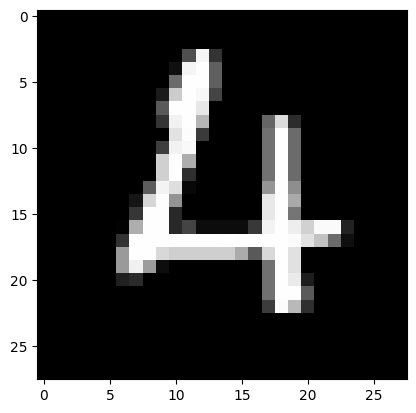

In [24]:
# Displays the 1050th image from the training set using a grayscale colormap
plt.imshow(x_train[1050], cmap = "gray")

In [25]:
# This is a basic deep learning model that learns to recognize handwritten digits (0–9) using the MNIST dataset

model= keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),      # input Layer  Converts 2D image (28x28) into 1D vector (784 features)
    keras.layers.Dense(64 , activation= "relu"  ),  # Hidden layer with 64 neurons using ReLU activation
    keras.layers.Dense(10 , activation= "softmax" ) # Output layer with 10 neurons (one per digit class 0–9) [0.05,0.5,,,] using softmax activation
])

# adam Adaptive Moment Estimation > Optimizer
model.compile(
    optimizer='adam',                               # Optimizer used to update weights efficiently
    loss='sparse_categorical_crossentropy',         # Loss function for multi-class classification with integer labels
    metrics=['accuracy']                            # Metric used to evaluate model performance during training and testing
)

# Trains the model on training data and evaluates it on test/validation data during training
history = model.fit(
    x_train, y_train,
    epochs=5,                                       # Number of full passes through the training dataset
    validation_data=(x_test, y_test)                # Data used to evaluate model performance after each epoch
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9142 - loss: 0.3025 - val_accuracy: 0.9459 - val_loss: 0.1759
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9581 - loss: 0.1451 - val_accuracy: 0.9619 - val_loss: 0.1245
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9690 - loss: 0.1045 - val_accuracy: 0.9678 - val_loss: 0.1059
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9762 - loss: 0.0817 - val_accuracy: 0.9699 - val_loss: 0.0985
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9811 - loss: 0.0666 - val_accuracy: 0.9714 - val_loss: 0.0931


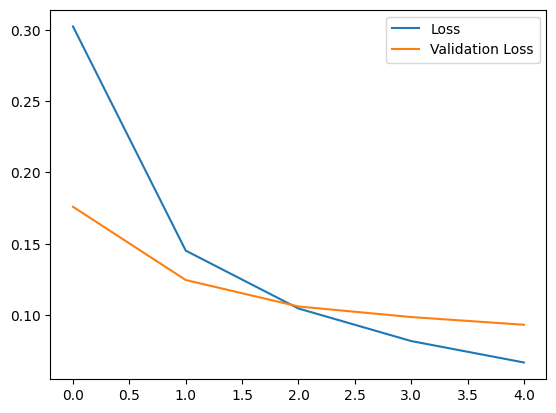

In [26]:
# Plots the training loss & validation loss of the modeel
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

In [27]:
# the model predicts the label (digit class) for a single image
prediction = model.predict(x_test[14].reshape(1, 28, 28))  # 10 pred
prediction  # Prints the predicted probabilities for each digit class

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


array([[1.29329591e-09, 9.99736965e-01, 1.32201885e-05, 1.84920485e-04,
        1.88597187e-06, 1.16564935e-08, 2.14141409e-07, 1.86980633e-05,
        3.87383770e-05, 5.28861756e-06]], dtype=float32)

In [28]:
# `np.argmax` returns the index of the maximum value in the array
print("Prediction:", np.argmax(prediction)) 

Prediction: 1


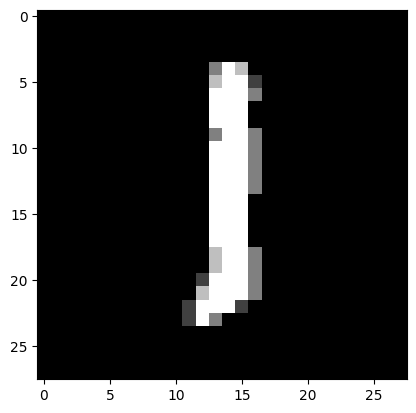

In [29]:
# Displays the 14th image from the test set after prediction to compare the actual and the predicted value
plt.imshow(x_test[14], cmap = "gray")

The model successfully classified test sample 14 as digit 1, which was the correct label

--- 

## Section 2 —  Data Splitting, Regularization & Early Stopping

### **Key Concepts Introduced:**
#### **1. Proper Dataset Splitting**
**General Idea**

- **Training set**: The model learns from this data.  
- **Validation set**: Used during training to tune hyperparameters and prevent overfitting.  
- **Test set**: Kept aside until the very end to measure the model’s *true performance* on completely unseen data.  

**Important Note**:  
If you use `x_test` directly as your validation set, this is a mistake.  
Why? Because you will end up tuning your model on the same data that you later claim to be your “unseen test set,” which makes the final evaluation biased.  

The correct workflow:
1. Split the dataset into **train + test** (e.g., 80% train, 20% test).  
2. From the **train** portion, further split into **train + validation** (e.g., 70% train, 10% validation, 20% test).  
3. Use the **validation set** only for model tuning.  
4. Use the **test set** once at the end for the final unbiased performance check.

#### **2. Regularization Techniques**
- Adding **Dropout** layers to reduce overfitting
- Using **EarlyStopping** to detect convergence and stop training

#### **3. Improved Model Pipeline**
- Training over more epochs
- Monitoring training vs. validation performance
- Evaluating on the final test set
- Predicting and analyzing results


---


In [30]:
# 1) Load Dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values (0-255 -> 0-1)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 2) Split Validation Set from Training Set
# Reserve last 5000 samples for validation
x_val = x_train[-5000:] # last 5000 rows
y_val = y_train[-5000:] # last 5000 rows

x_tr = x_train[:-5000]
y_tr = y_train[:-5000]
print("Train shape:", x_tr.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

# 60,000 train >> 55,000 train + 5000 val
# 10,000 test

Train shape: (55000, 28, 28)
Validation shape: (5000, 28, 28)
Test shape: (10000, 28, 28)


In [31]:
# 3) Build Model
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.1),  
    keras.layers.Dense(10, activation="softmax")
])

# 4) Compile Model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])


# 5) Train with Validation Set
callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
]

history = model.fit(
    x_tr, y_tr,
    epochs=20,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=callbacks
)

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9162 - loss: 0.2911 - val_accuracy: 0.9678 - val_loss: 0.1235
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9605 - loss: 0.1318 - val_accuracy: 0.9746 - val_loss: 0.0918
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9712 - loss: 0.0948 - val_accuracy: 0.9746 - val_loss: 0.0832
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9770 - loss: 0.0746 - val_accuracy: 0.9778 - val_loss: 0.0794
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9804 - loss: 0.0610 - val_accuracy: 0.9790 - val_loss: 0.0745
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9843 - loss: 0.0509 - val_accuracy: 0.9820 - val_loss: 0.0690
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9862 - loss: 0.0438 - val_accuracy: 0.9790 - val_loss: 0.0725
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9888 - loss: 0.0360 - 

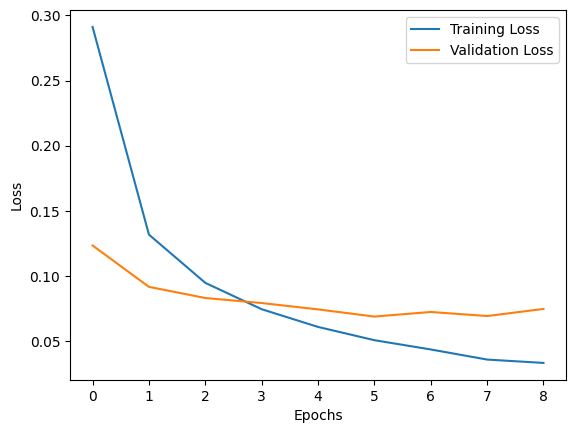

In [32]:
# 6) Plot Training vs Validation Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [33]:
# 7) Evaluate on Test Set
print("Final evaluation on test data:")
model.evaluate(x_test, y_test)

Final evaluation on test data:
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9776 - loss: 0.0698


[0.06981244683265686, 0.9775999784469604]

In [34]:
# 8) Predict Example
# `np.argmax` returns the index of the maximum value in the array
sample = x_test[13].reshape(1, 28, 28)
pred = model.predict(sample)
print("Predicted Label:", np.argmax(pred))
print("True Label:", y_test[13])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Predicted Label: 0
True Label: 0


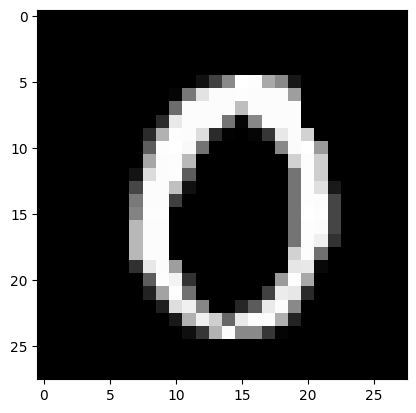

In [35]:
# 9)  Displays the 13th image from the test set after prediction to compare the actual and the predicted value
plt.imshow(x_test[13], cmap="gray")
plt.show()

The model successfully classified test sample 13 as digit 0, which was the correct label

---

## Section 3 — Student Tasks: Deep Learning Mastery


---

## Part 1 — Core Model Understanding & Prediction Behavior


---

### **Task 1 — Deep Prediction Analysis**
Select **three samples** from `x_test` and:

1. Run `model.predict(...)` on each sample.  
2. Print the **Predicted Label** and **True Label**.  
3. Provide a conceptual explanation of the result by referencing:
   - How the forward pass transforms inputs through layers.  
   - The role of activation functions (ReLU, Softmax).  
   - How the optimizer (Adam) may have shaped weight updates during training.

The objective is not to simply report results, but to analyze *why* the model predicted correctly or incorrectly.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Predicted Label: 0
Confidence: 99.99845
True Label: 0


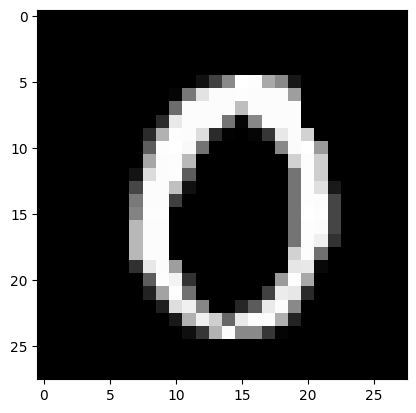

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Predicted Label: 1
Confidence: 99.99572
True Label: 1


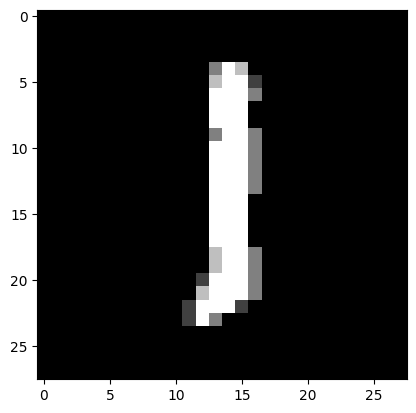

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Predicted Label: 5
Confidence: 99.68286
True Label: 5


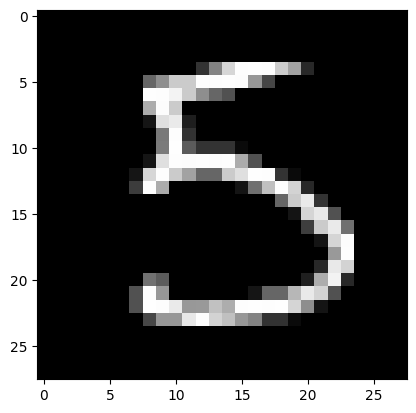

In [36]:
# select 3 samples from test set and predict then display : the actual and the predicted value

os.makedirs("results/predictions", exist_ok=True)

sample1 = x_test[13].reshape(1, 28, 28)
sample2 = x_test[14].reshape(1, 28, 28)
sample3 = x_test[15].reshape(1, 28, 28)

samples = [sample1 , sample2 , sample3]
  
for i, sample in enumerate(samples, start=13):
    pred = model.predict(sample)
    print("Predicted Label:", np.argmax(pred))
    print("Confidence:", np.max(pred)*100)  
    print("True Label:", y_test[i])
    plt.imshow(sample.reshape(28, 28), cmap="gray")
    plt.savefig(f"results/predictions/Task01_sample_{i}_pred.png")
    plt.show()

---

### **Task 2 — Custom Image Generalization Test**
Create a handwritten digit using a drawing tool and load it into the model. After preprocessing (grayscale, resizing to 28×28, normalization), run prediction and analyze:

- Did the model correctly classify the digit?  
- If not, why? Consider distribution shift, noise, or lack of augmentation.  
- How does this relate to representation learning in neural networks?

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Label: 2
Confidence: 98.76044
True Label: 5


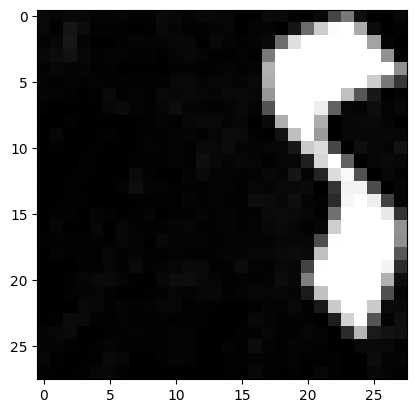

In [37]:
img = Image.open("results/predictions/Task02_handwritten_sample1_original.png")

# convert to grayscale and resize
img = img.convert('L')
img = img.resize((28, 28))

# convert to numpy array
img_array = np.array(img)

# make the background black and the text white
img_array = 255 - img_array

# normalize
img_array = img_array / 255.0

# reshape the image to (1, 28, 28) to match the input shape of the model
img_reshaped = img_array.reshape(1, 28, 28)

# print the predicted label and compare with the true label
prediction = model.predict(img_reshaped)
print("Predicted Label:", np.argmax(prediction))
print("Confidence:", np.max(prediction)*100)
print("True Label: 5")

# display the original image 
plt.imshow(img_array, cmap="gray")
plt.savefig(f"results/predictions/Task02_handwritten_sample1_processed.png")
plt.show()

In [38]:
# we can see from those results that the model does not only fail, but it is far from predicting the correct label 5 
# the confidence rate for 5 is 0.0035 which is too low
# the second highest confidence rate is 0.13 for lable 1 
print("\nSoftmax Output:")
for digit, prob in enumerate(prediction[0]):
    bar =  prob * 100
    print(f"  {digit}: {prob:.4f}")


Softmax Output:
  0: 0.0000
  1: 0.0000
  2: 0.9876
  3: 0.0000
  4: 0.0000
  5: 0.0007
  6: 0.0117
  7: 0.0000
  8: 0.0000
  9: 0.0000


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Predicted Label: 5
Confidence: 85.48755
True Label: 5


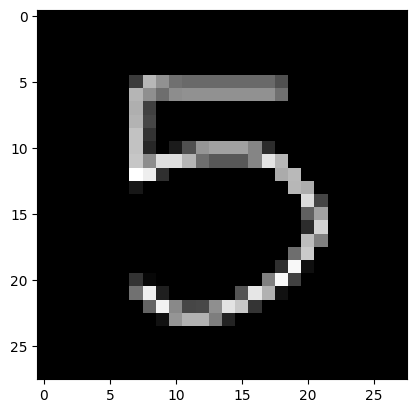

In [39]:
# now lets try to create a handwritten digit that fits the model requirements and test the model
img = Image.open("results/predictions/Task02_handwritten_sample2_original.png")

# convert to grayscale and resize
img = img.convert('L')
img = img.resize((28, 28))

# convert to numpy array
img_array = np.array(img)

# make the background black and the text white
img_array = 255 - img_array

# normalize
img_array = img_array / 255.0

# reshape the image to (1, 28, 28) to match the input shape of the model
img_reshaped = img_array.reshape(1, 28, 28)

# print the predicted label and compare with the true label
prediction = model.predict(img_reshaped)
print("Predicted Label:", np.argmax(prediction))
print("Confidence:", np.max(prediction)*100)
print("True Label: 5")

# display the original image 
plt.imshow(img_array, cmap="gray")
plt.savefig(f"results/predictions/Task02_handwritten_sample2_processed.png")
plt.show()

note the model succeeded in clasifying the digit since it fits the dataset tha model trained on



---

### **Task 3 — Epoch-Based Learning Curve Exploration**
Train the model with:
- 5 epochs  
- 10 epochs  
- 20 epochs

For each run:
1. Plot **loss vs. val_loss** and **accuracy vs. val_accuracy**.  
2. Identify signs of overfitting.  
3. Explain how the optimizer (Adam) influenced the speed and stability of convergence.

The focus is on understanding training dynamics.

In [40]:
# Train the model with different epochs

histories = [] # sroring the histories of the models with different epochs in a list to plot later
epoch_list = [5, 10, 20] # the epochs we want to train the model with

# Train the model with different epochs
for e in epoch_list:
    np.random.seed(42)     
    tf.random.set_seed(42)  
    
    print(f"\n--- Training with max {e} epochs ---")

    # build model
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(10, activation="softmax")
    ]) 

    # compile model
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # train model
    history = model.fit(x_tr, y_tr,epochs=e,batch_size=32,validation_data=(x_val, y_val))

    # store history of the model
    histories.append(history)





--- Training with max 5 epochs ---
Epoch 1/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9156 - loss: 0.2910 - val_accuracy: 0.9672 - val_loss: 0.1245
Epoch 2/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9599 - loss: 0.1361 - val_accuracy: 0.9762 - val_loss: 0.0953
Epoch 3/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9706 - loss: 0.0977 - val_accuracy: 0.9726 - val_loss: 0.0940
Epoch 4/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9767 - loss: 0.0770 - val_accuracy: 0.9758 - val_loss: 0.0870
Epoch 5/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9814 - loss: 0.0627 - val_accuracy: 0.9766 - val_loss: 0.0788

--- Training with max 10 epochs ---
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9145 - loss: 0.2933 - val_accuracy: 0.9670 - val_loss: 0.1206
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9599 - loss: 0.1352 - val_accuracy: 0.9744 - val_loss: 0.0920
Epoch 3/10
1719/1719 ━

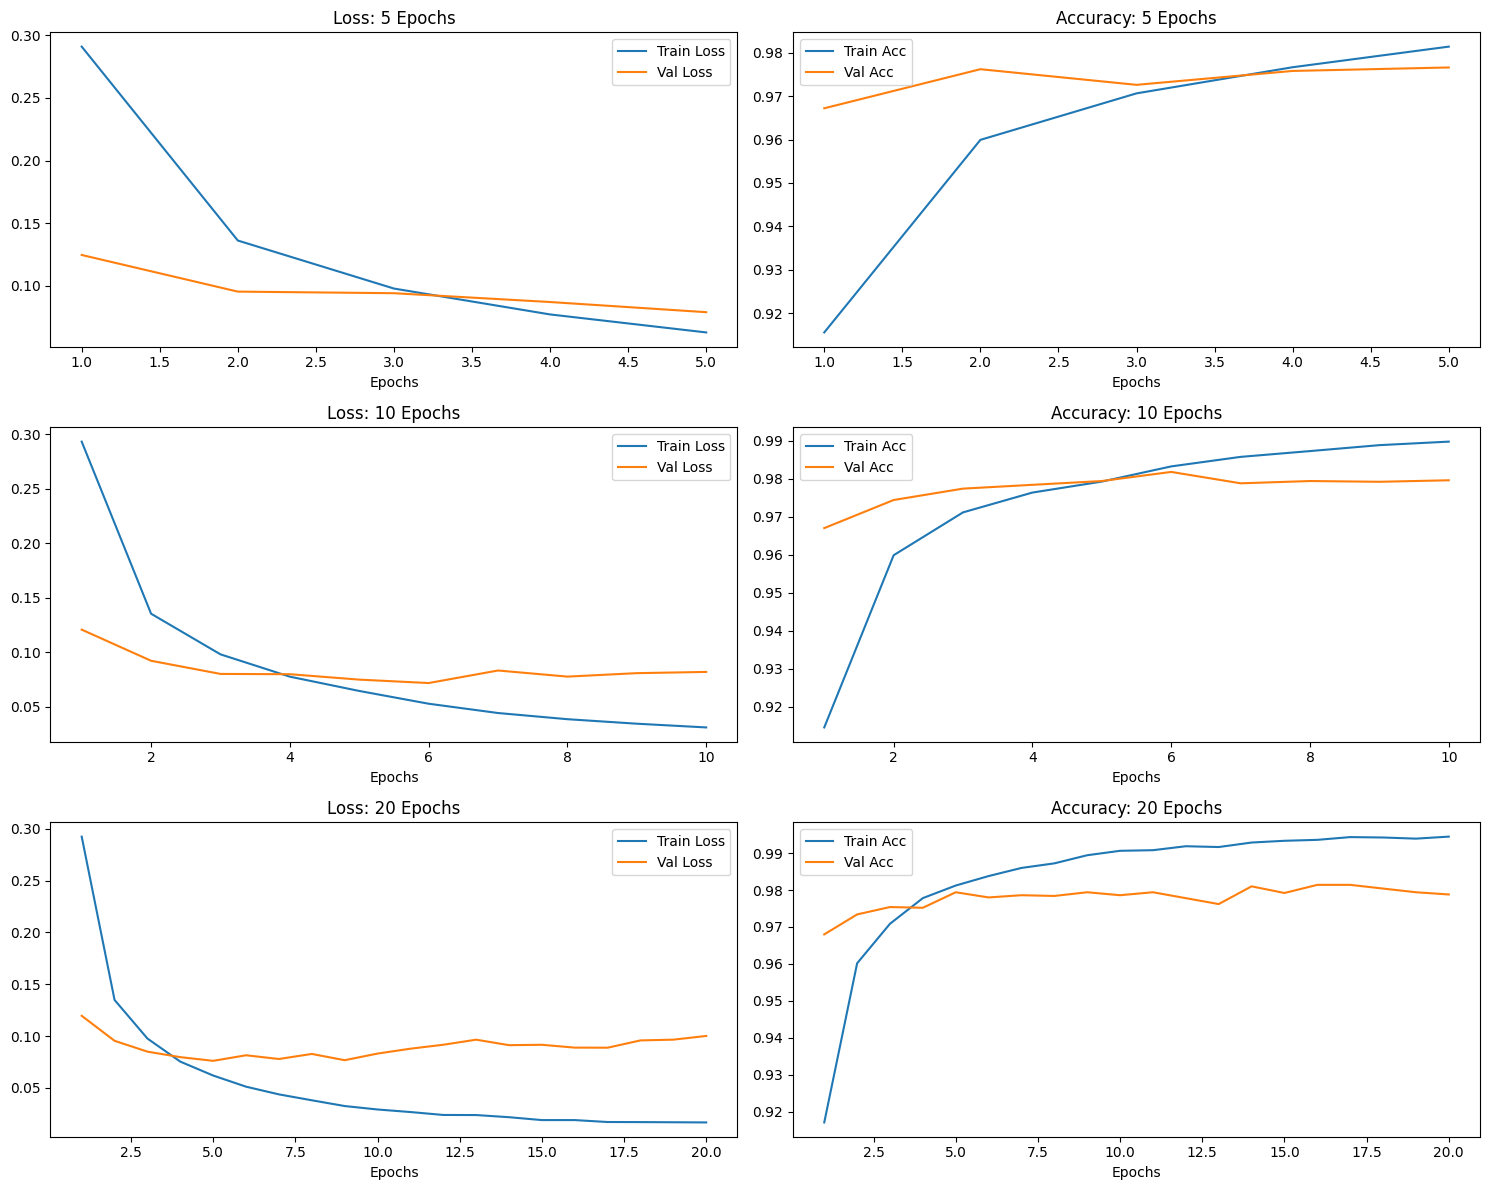

In [41]:
# Plot the loss and accuracy for each model with different epochs

os.makedirs("results/loss_curves", exist_ok=True)

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, h in enumerate(histories):
    e = epoch_list[i]
    x_axis = range(1, e + 1) 
    
    # plot loss (train and val)
    axes[i, 0].plot(x_axis, h.history['loss'], label='Train Loss')
    axes[i, 0].plot(x_axis, h.history['val_loss'], label='Val Loss')
    axes[i, 0].set_title(f"Loss: {e} Epochs")
    axes[i, 0].set_xlabel("Epochs") 
    axes[i, 0].legend()
    
    # plot accuracy (train and val)
    axes[i, 1].plot(x_axis, h.history['accuracy'], label='Train Acc')
    axes[i, 1].plot(x_axis, h.history['val_accuracy'], label='Val Acc')
    axes[i, 1].set_title(f"Accuracy: {e} Epochs")
    axes[i, 1].set_xlabel("Epochs") 
    axes[i, 1].legend()

plt.tight_layout()
plt.show()



---

### **Task 4 — EarlyStopping Behavior Analysis**
Enable EarlyStopping with:
```python
keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
```
Analyze:

1. At which epoch did training stop?  
2. Why does the validation loss control this decision?  
3. What happens if you increase patience (e.g., to 5)?  
4. Would a different optimizer (e.g., SGD) change the EarlyStopping pattern?  
5. Explain how EarlyStopping acts as an indirect form of regularization.

In [42]:
# train the model with different patiences (3 vs 5)

histories = [] # sroring the histories of the models with different patiences in a list to plot later
patience_list = [3,5] # the patience we want to train the model with

# Train the model with different patiences
for p in patience_list:
    np.random.seed(42)     
    tf.random.set_seed(42) 
    
    print(f"\n--- Training with max 20 epochs ---")
    print(f"\n--- Training with {p} patience ---")

    # build model
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(10, activation="softmax")
    ]) 

    # compile model
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # early stopping
    callbacks = [
    keras.callbacks.EarlyStopping(patience=p, restore_best_weights=True)
    ]

    # train model
    history1 = model.fit(x_tr, y_tr,epochs=20,batch_size=32,validation_data=(x_val, y_val), callbacks=callbacks)

    # store history of the model
    histories.append(history)


--- Training with max 20 epochs ---

--- Training with 3 patience ---
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9140 - loss: 0.2964 - val_accuracy: 0.9688 - val_loss: 0.1219
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9594 - loss: 0.1354 - val_accuracy: 0.9748 - val_loss: 0.0907
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9704 - loss: 0.0966 - val_accuracy: 0.9770 - val_loss: 0.0818
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9770 - loss: 0.0754 - val_accuracy: 0.9760 - val_loss: 0.0771
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9816 - loss: 0.0595 - val_accuracy: 0.9782 - val_loss: 0.0769
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9846 - loss: 0.0498 - val_accuracy: 0.9792 - val_loss: 0.0743
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9859 - loss: 0.0433 - val_accuracy: 0.9808 - val_loss: 0.0700
Epoch 8/20
1719/171

In [43]:
# train  the model with different optimizers (SGD)

print(f"\n--- Training with SGD optimizer ---")

# build model
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(10, activation="softmax")
]) 

# compile model
model.compile(optimizer='SGD', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# early stopping
callbacks = [
keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
]

# train model
history = model.fit(x_tr, y_tr,epochs=20,batch_size=32,validation_data=(x_val, y_val), callbacks=callbacks)

# store history of the model
histories.append(history)



--- Training with SGD optimizer ---
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8156 - loss: 0.7058 - val_accuracy: 0.9168 - val_loss: 0.3181
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8930 - loss: 0.3788 - val_accuracy: 0.9296 - val_loss: 0.2552
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9086 - loss: 0.3231 - val_accuracy: 0.9386 - val_loss: 0.2234
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9180 - loss: 0.2885 - val_accuracy: 0.9464 - val_loss: 0.2014
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9254 - loss: 0.2623 - val_accuracy: 0.9510 - val_loss: 0.1836
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9317 - loss: 0.2408 - val_accuracy: 0.9558 - val_loss: 0.1693
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9364 - loss: 0.2238 - val_accuracy: 0.9588 - val_loss: 0.1586
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step

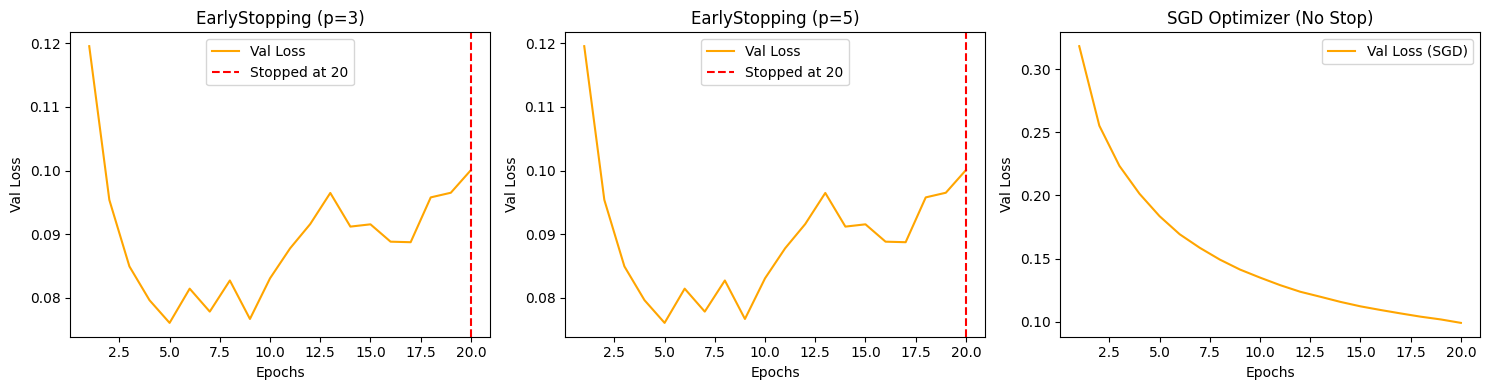

In [48]:
# plot the loss curves for the models with different patiences and optimizers

os.makedirs("results/loss_curves", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Plot for p = 3
epochs_p3 = range(1, len(histories[0].history['val_loss']) + 1)
axes[0].plot(epochs_p3, histories[0].history['val_loss'], label='Val Loss', color='orange')
axes[0].axvline(x=len(histories[0].history['val_loss']), color='r', linestyle='--', label=f"Stopped at {len(histories[0].history['val_loss'])}")
axes[0].set_title("EarlyStopping (p=3)")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Val Loss")
axes[0].legend()

# 2) Plot for p = 5
epochs_p5 = range(1, len(histories[1].history['val_loss']) + 1)
axes[1].plot(epochs_p5, histories[1].history['val_loss'], label='Val Loss', color='orange')
axes[1].axvline(x=len(histories[1].history['val_loss']), color='r', linestyle='--', label=f"Stopped at {len(histories[1].history['val_loss'])}")
axes[1].set_title("EarlyStopping (p=5)")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Val Loss")
axes[1].legend()

# 3) Plot for SGD
epochs_sgd = range(1, len(history.history['val_loss']) + 1)
axes[2].plot(epochs_sgd, history.history['val_loss'], label='Val Loss (SGD)', color='orange')
axes[2].set_title("SGD Optimizer (No Stop)")
axes[2].set_xlabel("Epochs")
axes[2].set_ylabel("Val Loss")
axes[2].legend()

plt.tight_layout()
plt.savefig("results/loss_curves/Task04_early_stopping_comparison2.png")
plt.show()

---

## Part 2 — Regularization & Optimization Mastery



---

### **Task 5 — Dropout Ablation Study** (Selfstudy)
Modify the model to test three configurations:
- No Dropout  
- Dropout = 0.1  
- Dropout = 0.3

For each configuration:
1. Train the model.  
2. Plot training vs. validation loss.  
3. Compare overfitting levels.  
4. Explain how Dropout encourages robust representations by preventing neuron co-adaptation.


In [49]:
# Train the model with different dropouts 

histories = [] # sroring the histories of the models with different dropouts in a list to plot later
dropouts_list = [0, 0.1, 0.3] # the dropouts we want to train the model with

# Train the model with different dropouts
for d in dropouts_list:
    np.random.seed(42)      
    tf.random.set_seed(42)  
    
    print(f"\n--- Training with  {d} dropout ---")

    # build model
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(d),
        keras.layers.Dense(10, activation="softmax")
    ]) 

    # compile model
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # train model
    history = model.fit(x_tr, y_tr,epochs=20,batch_size=32,validation_data=(x_val, y_val))

    # store history of the model
    histories.append(history)


--- Training with  0 dropout ---
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9209 - loss: 0.2724 - val_accuracy: 0.9682 - val_loss: 0.1200
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9646 - loss: 0.1179 - val_accuracy: 0.9716 - val_loss: 0.0945
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9764 - loss: 0.0810 - val_accuracy: 0.9724 - val_loss: 0.0911
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9827 - loss: 0.0597 - val_accuracy: 0.9738 - val_loss: 0.0933
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9874 - loss: 0.0447 - val_accuracy: 0.9738 - val_loss: 0.0943
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9908 - loss: 0.0337 - val_accuracy: 0.9758 - val_loss: 0.0905
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9935 - loss: 0.0251 - val_accuracy: 0.9754 - val_loss: 0.0984
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - 

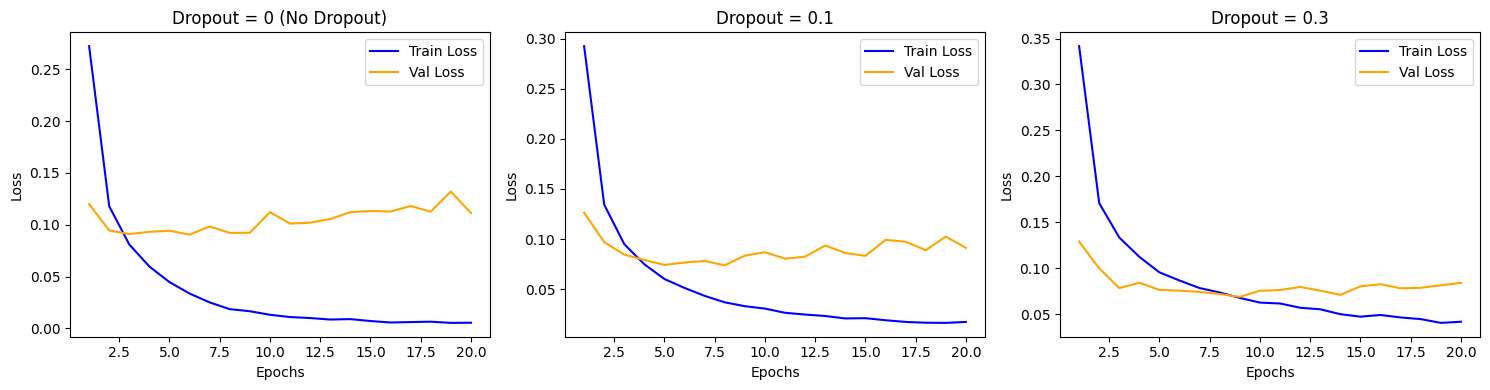

In [51]:
# plot the loss curves for the models with different dropouts

os.makedirs("results/loss_curves", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Plot for Dropout = 0
epochs = range(1, 21)
axes[0].plot(epochs, histories[0].history['loss'], label='Train Loss', color='blue')
axes[0].plot(epochs, histories[0].history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title("Dropout = 0 (No Dropout)")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2) Plot for Dropout = 0.1
axes[1].plot(epochs, histories[1].history['loss'], label='Train Loss', color='blue')
axes[1].plot(epochs, histories[1].history['val_loss'], label='Val Loss', color='orange')
axes[1].set_title("Dropout = 0.1")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

# 3) Plot for Dropout = 0.3
axes[2].plot(epochs, histories[2].history['loss'], label='Train Loss', color='blue')
axes[2].plot(epochs, histories[2].history['val_loss'], label='Val Loss', color='orange')
axes[2].set_title("Dropout = 0.3")
axes[2].set_xlabel("Epochs")
axes[2].set_ylabel("Loss")
axes[2].legend()

plt.tight_layout()
plt.savefig("results/loss_curves/Task05_dropout_comparison.png")
plt.show()


---

### **Task 7 — Optimizer Comparison Challenge**  
Train four models using identical architecture but different optimizers:
- SGD (learning_rate=0.01)  
- SGD with Momentum  
- Adam  
- AdamW (Selfstudy)

For each optimizer:
1. Plot loss and accuracy curves.  
2. Compare convergence speed and stability.  
3. Discuss how each optimizer navigates the loss landscape differently.  
4. Explain why Adam often outperforms classical optimizers.

In [65]:
histories = []  # storing the histories of the models with different optimizers

# Define the 4 optimizer configurations
optimizers_list = [
    ('SGD',              keras.optimizers.SGD(learning_rate=0.01)),
    ('SGD & Momentum',     keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    ('Adam',             keras.optimizers.Adam(learning_rate=0.001)),
    ('AdamW', keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004)),
]

# Train the model with each optimizer
for opt_name, optimizer in optimizers_list:
    np.random.seed(42)      
    tf.random.set_seed(42)  
    
    print(f"\n--- Training with {opt_name} ---")

    # build model (same architecture for all)
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(10, activation="softmax")
    ])

    # compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # train model
    history = model.fit(x_tr, y_tr, epochs=20, batch_size=32, validation_data=(x_val, y_val))

    # store history
    histories.append(history)


--- Training with SGD ---
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8149 - loss: 0.7023 - val_accuracy: 0.9204 - val_loss: 0.3114
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8931 - loss: 0.3765 - val_accuracy: 0.9332 - val_loss: 0.2508
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9108 - loss: 0.3193 - val_accuracy: 0.9416 - val_loss: 0.2199
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9198 - loss: 0.2854 - val_accuracy: 0.9490 - val_loss: 0.1990
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9270 - loss: 0.2591 - val_accuracy: 0.9524 - val_loss: 0.1819
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9330 - loss: 0.2392 - val_accuracy: 0.9554 - val_loss: 0.1697
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9368 - loss: 0.2226 - val_accuracy: 0.9588 - val_loss: 0.1592
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accurac

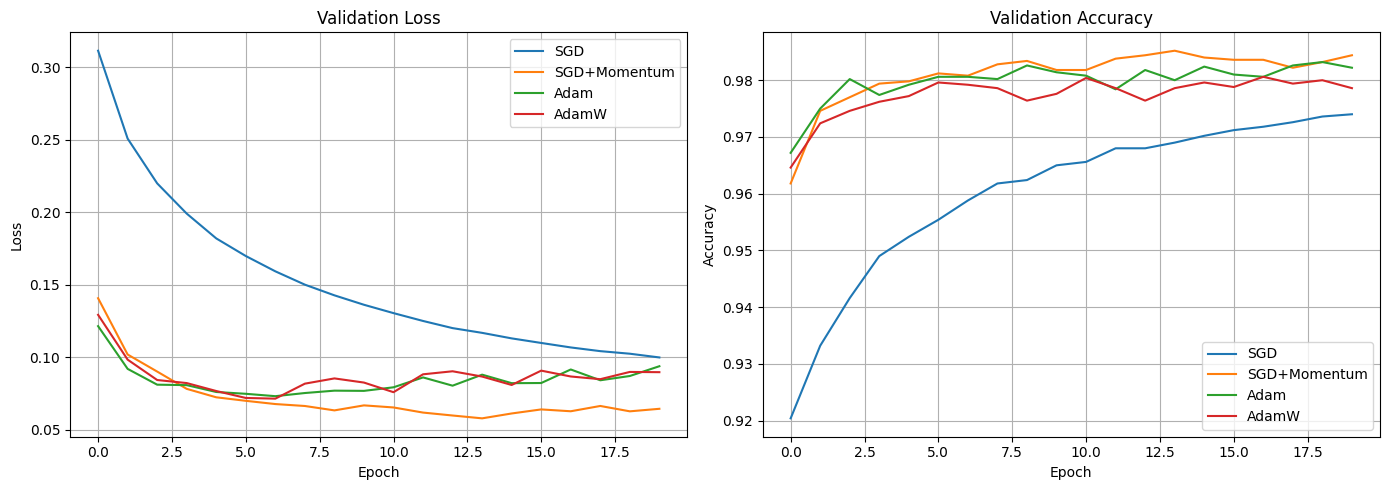

In [66]:
# Task 07 — Plotting Optimizer Comparison

os.makedirs("results/optimizer_tests", exist_ok=True)

optimizer_names = ['SGD', 'SGD+Momentum', 'Adam', 'AdamW']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
for i, history in enumerate(histories):
    axes[0].plot(history.history['val_loss'], label=optimizer_names[i])
axes[0].set_title('Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy curves
for i, history in enumerate(histories):
    axes[1].plot(history.history['val_accuracy'], label=optimizer_names[i])
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('results/optimizer_tests/Task07_optimizer_comparison.png', dpi=150)
plt.show()


---

### **Task 8 — Batch Size & Gradient Noise Experiment**
Train the model with batch sizes:
- 8  
- 32  
- 128

Discuss:
- Why smaller batches introduce gradient noise.  
- When this noise is beneficial (escaping local minima).  
- Why larger batches may converge faster but generalize worse.  
- How batch size affects the smoothness of loss curves.

In [59]:
# Train the model with different batch sizes

histories = [] # sroring the histories of the models with different batch sizes in a list to plot later
batch_size_list = [8, 32, 128] # the batch sizes we want to train the model with

# Train the model with different batch sizes
for b in batch_size_list:
    np.random.seed(42)      
    tf.random.set_seed(42)  
    
    print(f"\n--- Training with  {b} batch_size ---")

    # build model
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(10, activation="softmax")
    ]) 

    # compile model
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


    # train model
    history = model.fit(x_tr, y_tr,epochs=20,batch_size=b,validation_data=(x_val, y_val))

    # store history of the model
    histories.append(history)



--- Training with  8 batch_size ---
Epoch 1/20


C:\Users\Dema\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6875/6875 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9275 - loss: 0.2455 - val_accuracy: 0.9674 - val_loss: 0.1110
Epoch 2/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9648 - loss: 0.1177 - val_accuracy: 0.9756 - val_loss: 0.0903
Epoch 3/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9730 - loss: 0.0863 - val_accuracy: 0.9766 - val_loss: 0.0791
Epoch 4/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9783 - loss: 0.0680 - val_accuracy: 0.9776 - val_loss: 0.0833
Epoch 5/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step - accuracy: 0.9808 - loss: 0.0592 - val_accuracy: 0.9786 - val_loss: 0.0860
Epoch 6/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9830 - loss: 0.0505 - val_accuracy: 0.9776 - val_loss: 0.0907
Epoch 7/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9851 - loss: 0.0448 - val_accuracy: 0.9798 - val_loss: 0.0877
Epoch 8/20
6875/6875 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9874 - loss: 0.0386 - val

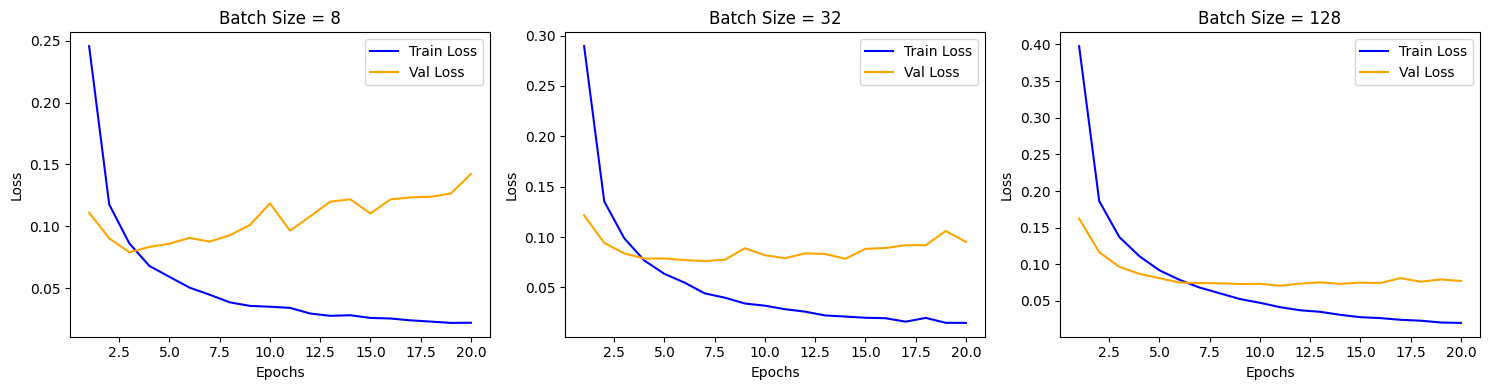

In [61]:
#  plot the loss curves for the models with different batch sizes 

os.makedirs("results/loss_curves", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Plot for Batch Size = 8
epochs = range(1, 21)
axes[0].plot(epochs, histories[0].history['loss'], label='Train Loss', color='blue')
axes[0].plot(epochs, histories[0].history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title("Batch Size = 8")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2) Plot for Batch Size = 32
axes[1].plot(epochs, histories[1].history['loss'], label='Train Loss', color='blue')
axes[1].plot(epochs, histories[1].history['val_loss'], label='Val Loss', color='orange')
axes[1].set_title("Batch Size = 32")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

# 3) Plot for Batch Size = 128
axes[2].plot(epochs, histories[2].history['loss'], label='Train Loss', color='blue')
axes[2].plot(epochs, histories[2].history['val_loss'], label='Val Loss', color='orange')
axes[2].set_title("Batch Size = 128")
axes[2].set_xlabel("Epochs")
axes[2].set_ylabel("Loss")
axes[2].legend()

plt.tight_layout()
plt.savefig("results/loss_curves/Task08_batchsize_comparison.png")
plt.show()


---

### **Task 9 — Activation Function Swap (ReLU vs Tanh vs GELU)**
Modify the model by replacing ReLU with:
- Tanh  
- Softsign   (Selfstudy)
- GELU (Selfstudy)

Analyze:
- How each activation affects gradient flow.  
- Which activations risk vanishing gradients.  
- Why GELU performs well in Transformer architectures.  
- Why ReLU remains preferred for many MLP and CNN models.



In [ ]:
# Train the model with different activation functions

histories = [] # sroring the histories of the models with different activation functions in a list to plot later
activation_functions_list = ['relu','tanh', 'gelu'] # the activation functions we want to train the model with

# Train the model with different activation functions
for a_func in activation_functions_list:
    np.random.seed(42)      
    tf.random.set_seed(42) 
    
    print(f"\n--- Training with  {a_func} activation ---")

    # build model
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(128, activation=a_func),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(10, activation="softmax")
    ]) 

    # compile model
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # train model
    history = model.fit(x_tr, y_tr,epochs=20,batch_size=32,validation_data=(x_val, y_val))

    # store history of the model
    histories.append(history)


--- Training with  relu activation ---
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9144 - loss: 0.2946 - val_accuracy: 0.9670 - val_loss: 0.1210
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9587 - loss: 0.1374 - val_accuracy: 0.9726 - val_loss: 0.0948
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9702 - loss: 0.0980 - val_accuracy: 0.9764 - val_loss: 0.0832
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9762 - loss: 0.0777 - val_accuracy: 0.9788 - val_loss: 0.0780
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9803 - loss: 0.0639 - val_accuracy: 0.9776 - val_loss: 0.0786
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9827 - loss: 0.0538 - val_accuracy: 0.9798 - val_loss: 0.0773
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9853 - loss: 0.0459 - val_accuracy: 0.9810 - val_loss: 0.0753
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/s

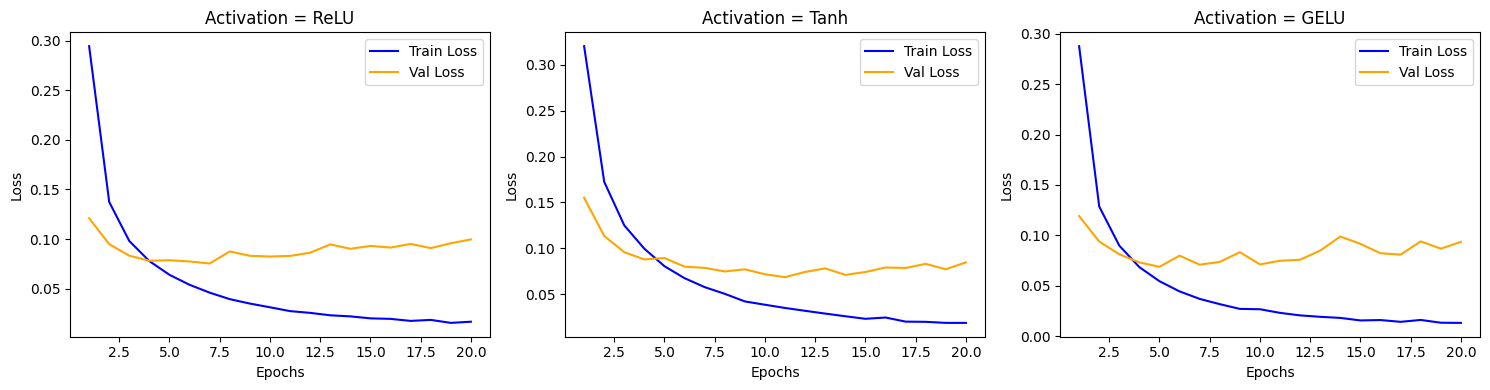

In [63]:
# plot the loss curves for the models with different activation functions

os.makedirs("results/loss_curves", exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

epochs = range(1, 21)

# 1) Plot for ReLU
axes[0].plot(epochs, histories[0].history['loss'], label='Train Loss', color='blue')
axes[0].plot(epochs, histories[0].history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title("Activation = ReLU")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2) Plot for Tanh
axes[1].plot(epochs, histories[1].history['loss'], label='Train Loss', color='blue')
axes[1].plot(epochs, histories[1].history['val_loss'], label='Val Loss', color='orange')
axes[1].set_title("Activation = Tanh")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

# 3) Plot for GELU
axes[2].plot(epochs, histories[2].history['loss'], label='Train Loss', color='blue')
axes[2].plot(epochs, histories[2].history['val_loss'], label='Val Loss', color='orange')
axes[2].set_title("Activation = GELU")
axes[2].set_xlabel("Epochs")
axes[2].set_ylabel("Loss")
axes[2].legend()

plt.tight_layout()
plt.savefig("results/loss_curves/Task09_activation_comparison.png")
plt.show()


---

This full task set is designed to build a deep understanding of neural networks, optimization, and regularization—bridging theory with hands-on experimentation in a structured, progress